## AI usage statement

*Fill this in before you submit the notebook — it is part of your submission.*

**Did you use AI tools (e.g. ChatGPT, Claude, Copilot, Gemini) for this notebook?** Replace `[ ]` by `[x]`:

- [ ] No, I did not use any AI tools.
- [ ] Yes, as described in the table below.

| Tool (name/version) | What I used it for (e.g. explaining a concept, writing or debugging code, phrasing an answer) | Tasks / cells | How I checked the result |
|---|---|---|---|
| | | | |

**I confirm** that I understand every piece of code and every answer in this notebook and can explain them myself.

Name: … &nbsp;&nbsp; Date: …



# Graph Neural Networks for Polymer Band Gap Prediction

This tutorial guides you through building a **Graph Neural Network (GNN)** to predict the
electronic band gap ($E_g$) of polymers from their chemical repeat-unit structure. The band
gap (energy separation between the valence and conduction bands) is a critical design target
for organic photovoltaics, light-emitting devices, or gate dielectric applications.

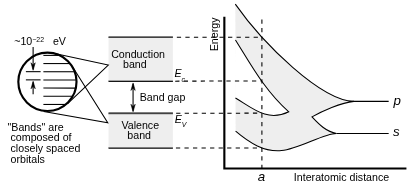

We represent each polymer repeat unit as a molecular graph
$\mathcal{G} = (\mathcal{V}, \mathcal{E})$
where nodes $v \in \mathcal{V}$ are atoms and edges $(u,v) \in \mathcal{E}$ are covalent
bonds. A GNN learns to map this variable-size graph to a scalar prediction through
iterative **message passing**.

**Learning objectives**

1. Parse polymer SMILES strings with RDKit and build PyG `Data` objects
2. Design chemically meaningful node feature vectors
3. Implement a graph-level task regression GNN using `GCNConv` and global mean pooling
4. Train and validate the model, monitoring overfitting via a held-out validation set
5. Assess predictive performance with MAE, RMSE, and $R^2$ on an independent test set

> **Structure of this notebook**
> - **Part A (Sections 1–7): the basics** — PSMILES → graph → GCN → training → evaluation → predictions.
> - **Part B (Sections B0–B3): beyond the basic GCN** — bond features, more expressive layers, polymer periodicity,
>   honest evaluation on unseen chemistry, and uncertainty.
>
> The dataset was explored and cleaned in the **fingerprints notebook**; here we load it with the same cleaning
> and the same train/validation/test split, so you can compare the GNN with your fingerprint models.
>
> **Runtime:** everything runs on a laptop CPU; Part A trains for ~2 minutes, Part B for ~6 minutes.

---
## Section 1: Setup and Imports

You will need those imports

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score

from rdkit import Chem
from rdkit.Chem import rdchem

from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, global_mean_pool

import torch_geometric

print(f"PyTorch            : {torch.__version__}")
print(f"PyTorch Geometric  : {torch_geometric.__version__}")
print(f"CUDA available     : {torch.cuda.is_available()}")

DEVICE = torch.device("cpu")
print(f"Using device       : {DEVICE}")

---
## Section 2: Data and Graphs

### 2.1 The cleaned dataset (given)

You explored this dataset in the **fingerprints notebook**. The cell below loads it and applies the same cleaning:
only the computed band gap (`Egc`) is used, and the 12 repeat units with a net charge are removed.
Each row is one polymer **repeat unit** written as PSMILES; the `[*]` atoms mark the chain connection points and are
kept as nodes in the graph.

In [ ]:
URL = (
    "https://raw.githubusercontent.com/kuennethgroup/materials_datasets"
    "/refs/heads/main/polymer_band_gap_computational/export.csv"
)
df = pd.read_csv(URL)
df = df[df["property"] == "Egc"].reset_index(drop=True)

net_charge = df["smiles"].apply(lambda s: sum(a.GetFormalCharge() for a in Chem.MolFromSmiles(s).GetAtoms()))
df = df[net_charge == 0].reset_index(drop=True)

print(f"Band-gap entries: {len(df)}   range {df['value'].min():.2f}–{df['value'].max():.2f} eV   "
      f"mean {df['value'].mean():.2f} ± {df['value'].std():.2f} eV")
df.head()

### 2.2 Building Molecular Graphs

A molecule with $N$ atoms becomes a PyG `Data` object containing:

- **Node feature matrix** $\mathbf{X} \in \mathbb{R}^{N \times d}$ — one row per atom
- **Edge index** $\mathbf{E} \in \mathbb{Z}^{2 \times 2|\text{bonds}|}$ — each bond
  appears twice (both directions) to model undirected communication
- **Graph label** $y \in \mathbb{R}$ — the band gap in eV

We use a 25-dimensional node feature vector:

| Feature group | Encoding | Dimensionality |
|---|---|---|
| Atom symbol | One-hot over `{C, N, O, F, P, S, Cl, Br, Si, *}` | 10 |
| Degree | One-hot over $\{0,1,2,3,4,5,6\}$ | 7 |
| Is aromatic | Binary flag | 1 |
| Hybridisation | One-hot over `{SP, SP2, SP3, SP3D, SP3D2}` | 5 |
| Formal charge | Signed integer | 1 |
| Total H count | Non-negative integer | 1 |



In [ ]:
ATOM_SYMBOLS = ["C", "N", "O", "F", "P", "S", "Cl", "Br", "Si", "*"]
HYBRIDIZATIONS = [
    rdchem.HybridizationType.SP,
    rdchem.HybridizationType.SP2,
    rdchem.HybridizationType.SP3,
    rdchem.HybridizationType.SP3D,
    rdchem.HybridizationType.SP3D2,
]


def one_hot(value, choices):
    """Return a one-hot list; all-zero vector if value not in choices."""
    enc = [0] * len(choices)
    if value in choices:
        enc[choices.index(value)] = 1
    return enc


def atom_features(atom):
    """
    Compute the 25-dimensional feature vector for each atom.

    RDKit atom methods to compute the features.
    Use them line by line to get the necessary information about the atom:
    E.g. for the first feature (atom symbol), use `atom.GetSymbol()` to get the symbol of the atom, 
    then apply `one_hot()` to get the one-hot encoding: one_hot(atom.GetSymbol(), ATOM_SYMBOLS)
        atom.GetSymbol()          -> str,  e.g. 'C', 'N', '*'
        atom.GetDegree()          -> int,  number of explicit bonds
        atom.GetIsAromatic()      -> bool
        atom.GetHybridization()   -> rdchem.HybridizationType
        atom.GetFormalCharge()    -> int
        atom.GetTotalNumHs()      -> int,  includes implicit H

    Concatenate all features into a single list and return it.
    """
    
    


# Sanity check here, we use the method later
_mol = Chem.MolFromSmiles("[*]CC([*])C")
_feat = atom_features(_mol.GetAtomWithIdx(0))
print(f"Feature vector length : {len(_feat)}")

In [ ]:
# Next, we implement the main function to convert a SMILES string to a PyG Data object,
# which will be used to create our dataset.


def smiles_to_graph(smiles: str, y_val: float):
    """
    Convert a PSMILES string to a PyG Data object

    Instructions:
    1. Parse `smiles` with Chem.MolFromSmiles() from RDKit. 
       Return None on failure: `if mol is None: return None`.
    2. Build the node feature matrix x of shape [N, 25] using atom_features().
       Use torch.tensor(..., dtype=torch.float) and iterate over mol.GetAtoms() 
       to get the features for each atom.
    3. Build the edge_index tensor of shape [2, 2*num_bonds].
       Iterate over mol.GetBonds(); for each bond with atom indices i and j,
       add BOTH [i, j] and [j, i] to capture the undirected graph.
       Handle the edge case of zero bonds (isolated atoms).
       NOTE: bond.GetBeginAtomIdx() and bond.GetEndAtomIdx() give the indices of the two atoms in the bond.
       edge_list should be a list of pairs [[i, j], [j, i], ...] that you can convert to a torch tensor
    4. Create the label tensor y of shape [1, 1] from y_val.
    5. Return Data(x=x, edge_index=edge_index, y=y).
    """
    
    


# Test - should print a data object with num_nodes > 0
example = smiles_to_graph("[*]Oc1ccc(Cc2ccc([*])cc2)cc1", 3.85)
print(example)

In [ ]:
# After correctly completing the previous cell, this should run and produce statistics 
data_list, failed = [], 0

# df is the dataframe that you import at the beginning after filtering
for _, row in df.iterrows():
    g = smiles_to_graph(row['smiles'], row['value'])
    if g is not None:
        data_list.append(g)
    else:
        failed += 1

print(f'Converted : {len(data_list)}')
print(f'Failed    : {failed}')

num_nodes = [d.num_nodes for d in data_list]
num_edges = [d.num_edges // 2 for d in data_list]   # bonds, not directed edges
print(f'Atoms / repeat unit    : {np.mean(num_nodes):.1f} ± {np.std(num_nodes):.1f}')
print(f'Bonds / repeat unit    : {np.mean(num_edges):.1f} ± {np.std(num_edges):.1f}')


### 2.3 What does the GNN actually see?

Run the cell below. It draws the graph of polystyrene, `[*]CC([*])c1ccccc1`, and counts how many
atoms lie within $L$ bonds of the first `*` atom. After $L$ message-passing layers, a node
can only have received information from its **$L$-hop neighbourhood** (its *receptive field*).

In [ ]:
import networkx as nx
from torch_geometric.utils import to_networkx

ps_smiles = "[*]CC([*])c1ccccc1"  # polystyrene
ps_graph = smiles_to_graph(ps_smiles, 0.0)
ps_mol = Chem.MolFromSmiles(ps_smiles)
G = to_networkx(ps_graph, to_undirected=True)

colors = {"C": "#9e9e9e", "*": "#e57373", "O": "#64b5f6", "N": "#81c784", "S": "#fff176"}
labels = {a.GetIdx(): f"{a.GetSymbol()}{a.GetIdx()}" for a in ps_mol.GetAtoms()}
node_colors = [colors.get(a.GetSymbol(), "#ce93d8") for a in ps_mol.GetAtoms()]

fig, ax = plt.subplots(figsize=(5, 3.5))
nx.draw(G, nx.kamada_kawai_layout(G), labels=labels, node_color=node_colors,
        node_size=550, font_size=9, ax=ax)
ax.set_title("Polystyrene repeat unit as a graph")
plt.show()

hops = nx.single_source_shortest_path_length(G, 0)
for n_layers in range(1, 6):
    seen = sum(dist <= n_layers for dist in hops.values())
    print(f"after {n_layers} layer(s): star atom 0 has seen {seen:2d} / {G.number_of_nodes()} atoms")

# How large are the repeat units in the whole dataset, measured in bonds (graph diameter)?
diameters = np.array([nx.diameter(to_networkx(g, to_undirected=True)) for g in data_list])
print(f"\nGraph diameter in the dataset: median {np.median(diameters):.0f}, max {diameters.max()}")
print(f"Repeat units larger than 3 hops across: {np.mean(diameters > 3):.0%}")

**Questions:**
1. Our model (Section 4) uses **3** convolution layers. Can every atom "see" the whole repeat unit?
2. Look at the row of the `*` atom in the feature matrix (`ps_graph.x[0]`). What distinguishes it from a carbon atom?
3. Should the model be able to tell `[*]CC[*]` and `[*]CCCC[*]` apart? Should it *want* to? (We come back to this in Part B.)

---
## Section 3: Creating the PyG Dataset and DataLoaders

### Batching variable-size graphs

Molecular graphs vary in node and edge count. PyTorch Geometric and other tools handle
this through **disjoint graph batching**: $B$
graphs are merged into a single large disconnected graph by block-diagonalising their
adjacency matrices and vertically stacking node features:

$$
\mathbf{X}^{\text{batch}} = \begin{bmatrix} \mathbf{X}_1 \\ \vdots \\ \mathbf{X}_B \end{bmatrix}
\in \mathbb{R}^{(\sum_i N_i) \times d}, \qquad
\mathbf{A}^{\text{batch}} = \operatorname{blkdiag}(\mathbf{A}_1, \ldots, \mathbf{A}_B)
$$

A companion `batch` vector of shape $[\sum_i N_i]$ records which graph each node belongs
to, enabling backtracing and graph-level aggregations like `global_mean_pool`.

We use the same 70 / 15 / 15 % train / validation / test split as in the fingerprints notebook (the split itself is
given); your task is to wrap the three sets in PyG `DataLoader`s.


In [ ]:
# Same split as in the fingerprints notebook (given)
import random

random.seed(42)
torch.manual_seed(42)
np.random.seed(42)

n = len(data_list)
indices = list(range(n))
random.shuffle(indices)

n_train = int(0.70 * n)
n_val = int(0.15 * n)

train_data = [data_list[i] for i in indices[:n_train]]
val_data = [data_list[i] for i in indices[n_train : n_train + n_val]]
test_data = [data_list[i] for i in indices[n_train + n_val :]]

print(f"Train : {len(train_data)}")
print(f"Val   : {len(val_data)}")
print(f"Test  : {len(test_data)}")

BATCH_SIZE = 32

# TODO: Create train_loader (shuffle=True), val_loader (shuffle=False), and test_loader (shuffle=False)
# using PyG's DataLoader with BATCH_SIZE: train_loader = DataLoader(...) etc.


In [ ]:
# Run this after implementing the DataLoaders to see the structure of a batch
batch = next(iter(train_loader))
print('Batch object  :', batch)
print('x shape       :', batch.x.shape)            # [total_nodes, 25]
print('edge_index    :', batch.edge_index.shape)    # [2, total_directed_edges]
print('y shape       :', batch.y.shape)             # [batch_size, 1]
print('batch vector  :', batch.batch.shape)         # [total_nodes]
print('Unique graphs :', batch.batch.max().item() + 1)


---
## Section 4: Building the GNN Model

Architecture diagram:

```
Input  (25-dim node features)
  │
  ├── GCNConv(25 → 128) + BatchNorm1d + ReLU
  ├── GCNConv(128 → 128) + BatchNorm1d + ReLU
  └── GCNConv(128 → 128) + BatchNorm1d + ReLU
  │
  global_mean_pool          → [batch_size, 128]
  │
  ├── Linear(128 → 64) + ReLU + Dropout(p=0.2)
  └── Linear(64 → 1)          → predicted Eg (eV)
```


In [ ]:
class PolymerGNN(nn.Module):
    """Graph Convolutional Network for polymer band-gap regression."""

    def __init__(self, in_channels: int, hidden_channels: int = 128, num_conv_layers: int = 3):
        super().__init__()

        # 
        self.convs = nn.ModuleList()
        self.bns   = nn.ModuleList()

        # Convolution + BatchNorm layers
        # Instruction: Add GCNConv(in_channels, hidden_channels) and a matching
        #       BatchNorm1d(hidden_channels) as the first conv layer.
        # Then add (num_conv_layers - 1) additional GCNConv(hidden -> hidden)
        # layers, each with its own BatchNorm1d to self.convs and self.bns.

        # Regression head
        # Instruction: 
        # Define two linear layers: 
        # self.lin1 maps Linear(hidden_channels -> hidden_channels//2)
        # and maps self.lin2 Linear(hidden_channels//2 -> 1).

    def forward(self, x, edge_index, batch):
        """Forward pass of the GNN."""
        # Iterate over self.convs and self.bns.
        # For each (conv, bn) pair:
        #   x = conv(x, edge_index) # aggregate messages from neighbors
        #   x = bn(x) # to stabilize gradients
        #   x = F.relu(x) # activations function

        # Graph readout
        # Use global_mean_pool(x, batch) to obtain one vector per graph.


        # Regression head:
        # Apply lin1 + ReLU + Dropout(p=0.2, training=self.training) + lin2.
        # Return x.squeeze(-1) so the output shape is [batch_size].
    


IN_CHANNELS = data_list[0].x.shape[1]   
model = PolymerGNN(in_channels=IN_CHANNELS, hidden_channels=128, num_conv_layers=3).to(DEVICE)
print(model)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'\nTrainable parameters : {n_params:,}')


You will see something like:
```
PolymerGNN(
  (convs): ModuleList(
    (0): GCNConv(25, 128)
    (1-2): 2 x GCNConv(128, 128)
  )
  (bns): ModuleList(
    (0-2): 3 x BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (lin1): Linear(in_features=128, out_features=64, bias=True)
  (lin2): Linear(in_features=64, out_features=1, bias=True)
)

Trainable parameters : 45,441
```

---
## Section 5: Training Loop

We minimise the MSE:

$$
\mathcal{L}_{\text{MSE}} = \frac{1}{N}\sum_{i=1}^{N}\!\left(\hat{y}_i - y_i\right)^2
$$

MSE penalises large errors quadratically and assumes roughly Gaussian noise around the
true band gap.

We use **Adam** optimizer and a `ReduceLROnPlateau` scheduler.


In [ ]:
def train_epoch(model, loader, optimizer, criterion):
    """
    Run one full training epoch.

    Instructions:
    1. Set model to training mode.
    2. Loop over batches in loader.
       a. Move batch to DEVICE.
       b. Zero gradients.
       c. Forward pass: pred = model(batch.x, batch.edge_index, batch.batch)
       d. Compute loss against batch.y.squeeze(-1).
       e. Backpropagate and step the optimizer.
       f. Accumulate weighted loss (loss * batch.num_graphs) and sample count.
    3. Return mean loss (total_loss / total_samples).
    """
    model.train()
    total_loss, total_n = 0.0, 0
    for batch in loader:
        batch = batch.to(DEVICE)
        # Instructions: implement training step
    return total_loss / total_n

@torch.no_grad()
def evaluate(model, loader, criterion):
    """Evaluate on a DataLoader without gradient tracking; return mean MSE."""
    model.eval()
    total_loss, total_n = 0.0, 0

    for batch in loader:
        batch = batch.to(DEVICE)
        pred = model(batch.x, batch.edge_index, batch.batch)
        loss = criterion(pred, batch.y.squeeze(-1))

        total_loss += loss.item() * batch.num_graphs
        total_n += batch.num_graphs

    return total_loss / total_n


In [ ]:
# Some constants
EPOCHS = 150
LR = 1e-3
WEIGHT_DECAY = 1e-4

optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
criterion = nn.MSELoss()
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=15,
    min_lr=1e-5,
)

train_losses, val_losses = [], []

# Instructions: Fill in the training loop.
# For each epoch:
#   1. Call train_epoch -> tr_loss
#   2. Call evaluate on val_loader -> val_loss
#   3. Step the scheduler with val_loss
#   4. Append both losses to train_losses / val_losses
#   5. Print progress every 15 epochs and at epoch 1

In [ ]:
# Plot the training vs validation MSE error
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(train_losses, label='Train MSE', linewidth=1.5)
ax.plot(val_losses,   label='Val MSE',   linewidth=1.5, linestyle='--')
ax.set_xlabel('Epoch', fontsize=12)
ax.set_ylabel('MSE  (eV²)', fontsize=12)
ax.set_title('Learning Curves', fontsize=13)
ax.set_yscale('log')
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()


---
## Section 6: Evaluation

We report three standard regression metrics on the held-out test set: MAE, RMSE, and $R^2$.

The **parity plot** (predicted vs. actual) is the canonical visualisation in
computational materials science. Scatter close to the diagonal $\hat{y} = y$ indicates
good generalisation. Systematic offsets at either end of the range suggest that the model
struggles with the extremes of the band-gap distribution and may benefit from more data
or additional structural descriptors.


In [ ]:
@torch.no_grad()
def get_predictions(model, loader):
    """Collect all predictions and ground-truth labels as NumPy arrays."""
    model.eval()
    preds, targets = [], []
    for batch in loader:
        batch = batch.to(DEVICE)
        pred  = model(batch.x, batch.edge_index, batch.batch)
        preds.append(pred.cpu().numpy())
        targets.append(batch.y.squeeze(-1).cpu().numpy())
    return np.concatenate(preds), np.concatenate(targets)


y_pred, y_true = get_predictions(model, test_loader)

# Instruction: Compute and print the three metrics using scikit-learn / numpy.
#   mae  = mean_absolute_error(y_true, y_pred)
#   rmse = sqrt of mean squared error (compute manually with numpy)
#   r2   = r2_score(y_true, y_pred)


### 6.1 Is the model actually good? Compare with a baseline

An MAE of a few tenths of an eV only means something next to a reference. The simplest one is a
model that ignores the structure and always predicts the **mean band gap of the training set**.

**Task:** Compute MAE and $R^2$ of this mean-predictor on the test set and compare with the GNN.

In [ ]:
# TODO: collect the training labels (g.y.item() for g in train_data), predict their mean for every
# test sample, and print MAE and R² next to the GNN's numbers (mae, r2 from above).

**Questions:** Why do we use the mean of the *training* labels and not of the test labels?
Why is $R^2$ of the mean predictor (close to) zero?

In [ ]:
# TODO: Create a parity plot of predicted vs. actual band gaps (see parity_plot.png for reference)
#
# Requirements:
#   - Scatter plot of (y_true, y_pred) with semi-transparent markers
#   - A dashed diagonal line representing perfect prediction (y_hat = y)
#   - Equal aspect ratio and matching axis limits
#   - Axis labels: 'DFT Band Gap (eV)' and 'GNN Predicted Band Gap (eV)'
#   - A text box in the upper-left corner showing MAE, RMSE, and R²
#   - Save the figure to 'parity_plot.png' at 150 dpi



---
## Section 7: Use Your Model on Well-Known Polymers

A trained model is only useful if we can apply it to new structures.

**Task:** Write a function `predict(model, smiles_list)` that converts a list of PSMILES into graphs,
batches them, and returns the predicted band gaps. Use it on the polymers below and check, for each
one, whether the exact SMILES is already in the training data (then it is not really a prediction).

In [ ]:
KNOWN_POLYMERS = {
    "Polyethylene (PE)": "[*]CC[*]",
    "Polyethylene, written as [*]C[*]": "[*]C[*]",
    "Polypropylene (PP)": "[*]CC([*])C",
    "Polystyrene (PS)": "[*]CC([*])c1ccccc1",
    "Polytetrafluoroethylene (PTFE)": "[*]C(F)(F)C(F)(F)[*]",
    "Polyvinyl chloride (PVC)": "[*]CC([*])Cl",
    "Polyacetylene": "[*]C=C[*]",
    "Polythiophene": "[*]c1ccc([*])s1",
}


@torch.no_grad()
def predict(model, smiles_list):
    # TODO:
    # 1. model.eval()
    # 2. convert every SMILES with smiles_to_graph(s, 0.0)  (the label is a dummy value)
    # 3. put all graphs into ONE batch: next(iter(DataLoader(graphs, batch_size=len(graphs))))
    # 4. return the model output as a NumPy array
    pass


# TODO: print name, SMILES, predicted band gap, and whether the SMILES is in the training set
# (the training rows are df["smiles"].iloc[indices[:n_train]] if you used the variable names above)

**Questions:**
1. Do the predictions follow the chemical trends you found in the fingerprints notebook (Section 1.3) (saturated and fluorinated
   polymers → large gap; conjugated backbones → small gap)?
2. `[*]CC[*]` and `[*]C[*]` describe **the same polymer** (polyethylene). Does your model give the same
   band gap for both? Why not? *(Think about what the `*` atoms do to the graph.) Part B fixes this.*
3. Polyacetylene and polythiophene are classic conducting polymers. How many training examples are
   below 2 eV? How much would you trust predictions in this regime?

---
## Summary of Part A

You built a full GNN pipeline: PSMILES → RDKit molecule → PyG graph → GCN → band gap.

Answer briefly (2–3 sentences each):
1. Which **information about the molecule is lost** in our graph? (Hint: look at what goes into
   `x` and `edge_index` — is the bond *type* anywhere?)
2. The validation set was used for the learning-rate scheduler. Why must the **test set** stay
   untouched until the very end?
3. Our split is random. Would the test MAE be a fair estimate for polymers from a chemical family
   that is **not in the dataset**?

These three questions are the starting point of **Part B**.

---
# Part B — Beyond the Basic GCN

Part A ended with two weaknesses of the basic model:

1. The graph ignores **bond types** — a double bond looks exactly like a single bond.
2. A random train/test split may give an **over-optimistic** error estimate.

In Part B you address each of them and learn concepts that appear in almost every modern materials-GNN paper.

| Section | Concept | You implement |
|---|---|---|
| B1 | Edge (bond) features, unknown-element handling | `bond_features`, edge attributes |
| B2 | Expressive power: GCN vs. GINE | a configurable GNN class |
| B3 | Honest evaluation: out-of-distribution splits | a chemistry-based split |

Each section ends with **questions** — answer them in a markdown cell.

> Part B defines its own versions of some functions (`atom_features_b`, `smiles_to_graph_b`, …), so the cells of
> Part A keep working if you re-run them.

## B0: Additional Imports and Helpers (given)

In [ ]:
import copy
import random
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from rdkit import Chem, RDLogger
from rdkit.Chem import rdchem
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, GINEConv, global_add_pool, global_mean_pool

RDLogger.DisableLog("rdApp.*")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

---
## B1: Better Graph Features

### B1.1 Elements the model has never heard of

In the fingerprints notebook (Section 2.1) you found that iodine (`I`) and explicit hydrogen atoms (`H`) occur in the
data although they are not in `ATOM_SYMBOLS`. Part A's `atom_features` gave them an **all-zero** element encoding —
silently.

We fix this with an extra **"other"** slot in the one-hot vector, so unknown elements are at least
recognisable as "something else". The atom feature vector therefore grows from 25 to **26** entries.

In [ ]:
HYBRIDIZATIONS = [
    rdchem.HybridizationType.SP,
    rdchem.HybridizationType.SP2,
    rdchem.HybridizationType.SP3,
    rdchem.HybridizationType.SP3D,
    rdchem.HybridizationType.SP3D2,
]


def one_hot(value, choices):
    """One-hot list; all zeros if value not in choices."""
    return [int(value == c) for c in choices]


def one_hot_with_other(value, choices):
    """One-hot list with an extra last slot for values not in choices."""
    return one_hot(value, choices) + [int(value not in choices)]


def atom_features_b(atom):
    """26-dimensional atom features (Part A features + 'other element' slot)."""
    return (
        one_hot_with_other(atom.GetSymbol(), ATOM_SYMBOLS)  # 11
        + one_hot(atom.GetDegree(), list(range(7)))  # 7
        + [int(atom.GetIsAromatic())]  # 1
        + one_hot(atom.GetHybridization(), HYBRIDIZATIONS)  # 5
        + [float(atom.GetFormalCharge())]  # 1
        + [float(atom.GetTotalNumHs())]  # 1
    )


print(len(atom_features_b(Chem.MolFromSmiles("[*]CC([*])I").GetAtomWithIdx(4))), "features; iodine ->",
      atom_features_b(Chem.MolFromSmiles("[*]CC([*])I").GetAtomWithIdx(4))[:11])

### B1.2 Bond features as edge attributes

In PyG, edge features live in `data.edge_attr`, a tensor of shape `[num_edges, edge_dim]` whose row $k$
belongs to column $k$ of `edge_index`. Because each bond is stored twice ($i\to j$ and $j\to i$), its feature
vector must also be stored twice.

**Task B1.2:** Implement a 6-dimensional bond feature vector

| Feature | Encoding | Dim |
|---|---|---|
| Bond type | one-hot over `SINGLE, DOUBLE, TRIPLE, AROMATIC` | 4 |
| Conjugated | `bond.GetIsConjugated()` | 1 |
| In ring | `bond.IsInRing()` | 1 |

and complete `smiles_to_graph_b` so that it also returns `edge_attr`.

In [ ]:
BOND_TYPES = [
    rdchem.BondType.SINGLE,
    rdchem.BondType.DOUBLE,
    rdchem.BondType.TRIPLE,
    rdchem.BondType.AROMATIC,
]


def bond_features(bond):
    """6-dimensional bond features."""
    # TODO: one-hot of bond.GetBondType() over BOND_TYPES, then conjugated flag, then in-ring flag
    pass


def smiles_to_graph_b(smiles, y_val):
    mol = Chem.MolFromSmiles(smiles)
    x = torch.tensor([atom_features_b(a) for a in mol.GetAtoms()], dtype=torch.float)

    edges, edge_feats = [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        # TODO: append both directions to `edges` and the bond features (twice!) to `edge_feats`

    return Data(
        x=x,
        edge_index=torch.tensor(edges, dtype=torch.long).t().contiguous(),
        edge_attr=None,  # TODO: tensor of shape [num_edges, 6]
        y=torch.tensor([[y_val]], dtype=torch.float),
    )


example = smiles_to_graph_b("[*]C=CC(=O)c1ccc([*])cc1", 3.0)
print(example)  # expected: Data(x=[13, 26], edge_index=[2, 26], edge_attr=[26, 6], y=[1, 1])

Now convert the dataset with the new features. We **reuse the split from Part A** (given).

In [ ]:
graphs = [smiles_to_graph_b(s, y) for s, y in zip(df["smiles"], df["value"])]

train_idx = indices[:n_train]  # same split as in Part A and in the fingerprints notebook
val_idx = indices[n_train : n_train + n_val]
test_idx = indices[n_train + n_val :]


def subset(data, idx):
    return [data[i] for i in idx]


print(f"{len(graphs)} graphs  ->  train {len(train_idx)} / val {len(val_idx)} / test {len(test_idx)}")

---
## B2: How Expressive Is Your GNN?

All message-passing GNNs follow the same pattern (Part A, Section 4), but they differ in **how** neighbour
messages are combined:

| Layer | Update for node $v$ | Notes |
|---|---|---|
| `GCNConv` | $\mathbf{h}_v' = \mathbf{W}\sum_{u\in\mathcal{N}(v)\cup\{v\}} \frac{\mathbf{h}_u}{\sqrt{\tilde d_u \tilde d_v}}$ | a **weighted mean**; one linear layer; ignores edge features |
| `GINEConv` | $\mathbf{h}_v' = \mathrm{MLP}\big((1+\epsilon)\,\mathbf{h}_v + \sum_{u\in\mathcal{N}(v)} \mathrm{ReLU}(\mathbf{h}_u + \mathbf{W}_e\,\mathbf{e}_{uv})\big)$ | a **sum** + MLP; every message additionally sees the **bond features** $\mathbf{e}_{uv}$ |

**Why sum instead of mean?** A mean cannot count: a carbon with neighbours $\{\text{O}\}$ and one with
$\{\text{O}, \text{O}\}$ receive the *same* mean message. Xu et al. (*How Powerful are Graph Neural Networks?*,
ICLR 2019) showed that sum aggregation followed by an MLP is as powerful as the Weisfeiler–Lehman graph
isomorphism test — the theoretical upper bound for this family of GNNs.

**Task B2:** Complete `FlexGNN`, a model whose convolution type (`"gcn"`, `"gine"`) and pooling
(`"mean"`, `"add"`) can be chosen. Keep the rest of the architecture from Part A
(3 conv layers with BatchNorm + ReLU, pooling, `Linear(128→64)` + ReLU + Dropout(0.2), `Linear(64→1)`).

*Hints:* `GINEConv(nn, edge_dim=6)` takes the MLP as its first argument, e.g.
`nn.Sequential(nn.Linear(d_in, hidden), nn.ReLU(), nn.Linear(hidden, hidden))`.
`GINEConv` is called as `conv(x, edge_index, edge_attr)`, `GCNConv` as `conv(x, edge_index)`.

In [ ]:
class FlexGNN(nn.Module):
    def __init__(self, conv="gcn", pool="mean", in_dim=26, edge_dim=6, hidden=128, n_layers=3):
        super().__init__()
        self.conv_type = conv
        self.pool = {"mean": global_mean_pool, "add": global_add_pool}[pool]

        self.convs, self.bns = nn.ModuleList(), nn.ModuleList()
        for layer in range(n_layers):
            d_in = in_dim if layer == 0 else hidden
            # TODO: create the convolution `c` depending on `conv` ("gcn" or "gine")
            # and append it to self.convs together with a BatchNorm1d(hidden) in self.bns

        # TODO: regression head self.lin1 (hidden -> hidden // 2) and self.lin2 (hidden // 2 -> 1)

    def forward(self, data):
        x = data.x
        # TODO: message passing (remember: only GINE gets data.edge_attr), BatchNorm, ReLU
        # TODO: pooling with self.pool(x, data.batch)
        # TODO: regression head; return shape [batch_size]


for kind in ["gcn", "gine"]:
    m = FlexGNN(kind)
    print(f"{kind:5s}: {sum(p.numel() for p in m.parameters()):,} parameters")

The training helpers below are given. `fit` trains a fresh `FlexGNN` and keeps the weights of the epoch with
the best **validation** MAE (*early stopping by checkpoint*). We use 60 epochs to keep the runtime short.

In [ ]:
EPOCHS_B = 60


@torch.no_grad()
def predict_graphs(model, data, batch_size=256):
    model.eval()
    return torch.cat([model(b.to(DEVICE)).cpu() for b in DataLoader(data, batch_size=batch_size)]).numpy()


def targets_of(data):
    return np.array([g.y.item() for g in data])


def mae_of(model, data):
    return float(np.mean(np.abs(predict_graphs(model, data) - targets_of(data))))


def fit(conv, pool, train_data, val_data, seed=0, epochs=EPOCHS_B):
    set_seed(seed)
    model = FlexGNN(conv, pool).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=10, min_lr=1e-5)
    loader = DataLoader(train_data, batch_size=32, shuffle=True)

    best_val, best_state, t0 = float("inf"), None, time.time()
    for epoch in range(epochs):
        model.train()
        for batch in loader:
            batch = batch.to(DEVICE)
            opt.zero_grad()
            F.mse_loss(model(batch), batch.y.squeeze(-1)).backward()
            opt.step()
        val = mae_of(model, val_data)
        sched.step(val)
        if val < best_val:
            best_val, best_state = val, copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    print(f"  {conv}/{pool}: best val MAE {best_val:.3f} eV  ({time.time() - t0:.0f} s)")
    return model

### Experiment: GCN vs. GINE

Run the cell below (≈ 2 min). Both models see the same data split, the same number of epochs, and the
same hyper-parameters — only the convolution changes.

In [ ]:
train_g, val_g, test_g = subset(graphs, train_idx), subset(graphs, val_idx), subset(graphs, test_idx)

results = {}  # test MAE of every model in this notebook
models = {}
for kind in ["gcn", "gine"]:
    models[kind] = fit(kind, "mean", train_g, val_g)
    results[kind.upper()] = mae_of(models[kind], test_g)

pd.Series(results, name="test MAE (eV)").round(3).to_frame()

In [ ]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(results.keys(), results.values(), color=["#9e9e9e", "#1565c0"])
ax.set_ylabel("Test MAE (eV)")
ax.set_title("Same data, same training — different convolution")
for i, v in enumerate(results.values()):
    ax.text(i, v + 0.005, f"{v:.3f}", ha="center")
plt.tight_layout()
plt.show()

**Questions (B2):**
1. Rank the two models. Did the bond features help as much as you expected? Look again at the
   **atom** features: which bond information can the model already infer from aromaticity, hybridisation and
   hydrogen count of the two atoms of a bond?
2. GCN aggregates neighbour messages with a **weighted mean**; GINE uses a **sum** followed by an MLP, which
   can in principle "count" neighbours (a mean cannot tell a node with one O neighbour apart from one with
   two). Does this show up in the test MAE here? What could hide a true difference in expressiveness?
3. We compare models on **one** random split with **one** seed. How could you tell whether a difference of
   0.02 eV is real? Describe a protocol.

---
## B3: How Well Does the Model Really Generalise?

A random split puts close relatives of every test polymer into the training set. In materials discovery,
however, we usually want predictions for **new chemistry**. A simple way to measure this is a
**hold-out split by chemical family**: all polymers containing a certain element or group go to the test set,
and the model never sees any of them during training.

**Task B3:**
1. Find all polymers that contain **sulfur** (atom symbol `"S"`) — this will be the *out-of-distribution*
   (OOD) test set.
2. Randomly split the remaining polymers 70 / 15 / 15 into `tr_idx`, `va_idx`, and an *in-distribution* test
   set `id_idx` (use `set_seed(0)`).
3. Train a GINE on `tr_idx`/`va_idx` and report the MAE on both test sets. As a control, also report
   the MAE of the mean predictor (training mean) on both sets.

In [ ]:
# TODO 1: boolean list has_sulfur for every row of df, then ood_idx and rest
# TODO 2: set_seed(0), shuffle `rest`, split into tr_idx / va_idx / id_idx (70/15/15)
# TODO 3: build tr_g, va_g, id_g, ood_g from `graphs` and train:
#         model_ood = fit("gine", "mean", tr_g, va_g, seed=0)
# TODO 4: table with the MAE of model_ood and of the mean predictor on id_g and ood_g

**Questions (B3):**
1. How much larger is the OOD error compared to the in-distribution error? Why is the mean-predictor row an
   important control for this comparison?
2. Which of the two numbers would you report to an experimental collaborator who wants to screen a new family of
   sulfur-containing polymers?
3. Name two other ways to build "harder" splits for polymers (hint: scaffolds, clustering of fingerprints,
   time-based splits, property extrapolation).

---
## Summary

Run the cell below to collect the test MAEs of this notebook. They use the **same test set as the
fingerprints notebook** — compare them with your random-forest results there.

In [ ]:
summary = pd.Series(results, name="test MAE (eV)").round(3).to_frame()
summary

**Final questions:**
1. Summarise in three sentences what you would change in the Part A pipeline if you had to build a band-gap
   model for a real screening project, and why.
2. Every improvement in this notebook was evaluated on the same test set. What is the danger of doing that many
   times, and how would you avoid it?
3. In the fingerprints notebook a random forest on Morgan fingerprints reached a similar test MAE. GNNs learn features
   from the graph, fingerprints are hand-designed. What does each representation miss that the other has —
   and when would you choose a GNN over a fingerprint model?